In [ ]:
import numpy as np
import plotly.graph_objects as go

# --- CONFIGURACIÓN ---
b = 0.19
num_particles = 100000  # ¡Aquí aumentamos los puntos! (Prueba 200000 si tu PC es rápida)
dt = 0.05
steps = 300             # Aumenté un poco los pasos para que el atractor se forme mejor

# --- SIMULACIÓN ---
# Inicialización vectorizada (muy rápida)
x = np.random.uniform(-10, 10, num_particles)
y = np.random.uniform(-10, 10, num_particles)
z = np.random.uniform(-10, 10, num_particles)

# Bucle de integración (Ecuaciones de Thomas)
for _ in range(steps):
    dx = (-b * x + np.sin(y)) * dt
    dy = (-b * y + np.sin(z)) * dt
    dz = (-b * z + np.sin(x)) * dt

    x += dx
    y += dy
    z += dz

# --- VISUALIZACIÓN ---
fig = go.Figure(data=[go.Scatter3d(
    x=x,
    y=y,
    z=z,
    mode='markers',
    marker=dict(
        size=1.5,              # Puntos más pequeños para mayor detalle
        color=z + x - y,       # Combinación de coordenadas para un color más complejo
        colorscale='Inferno',  # Paleta de colores 'fuego'
        opacity=0.3            # Más transparencia para ver la estructura interna
    )
)])

fig.update_layout(
    title=f"High Density Thomas' Attractor ({num_particles} particles)",
    width=900,
    height=800,
    template="plotly_dark",
    scene=dict(
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        bgcolor='black'
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

Generando datos del atractor...
Renderizando animación (esto puede tardar 1-2 minutos)...
¡Listo! Archivo guardado: thomas_attractor_canva.gif
Busca el icono de la carpeta 📁 a la izquierda en Colab para descargarlo.


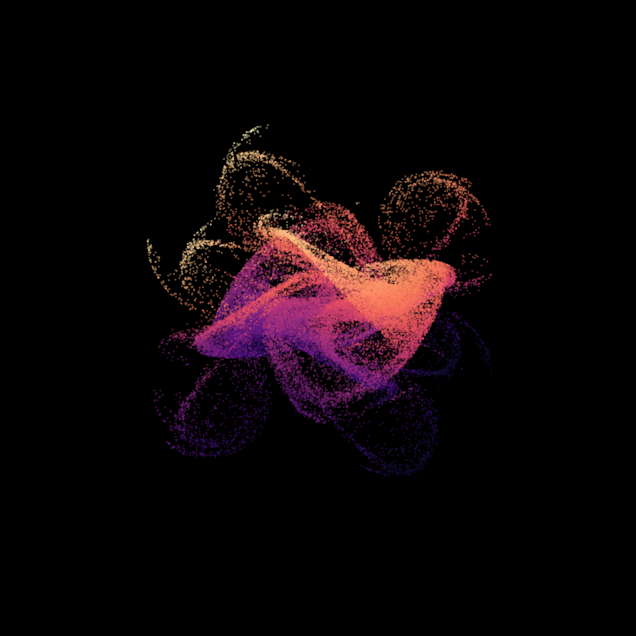

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# --- 1. Configuración ---
b = 0.19
num_particles = 50000  # Un poco menos de puntos para que el GIF se genere rápido
dt = 0.05
steps = 200
frames = 120           # Duración de la animación (cantidad de cuadros)

print("Generando datos del atractor...")

# --- 2. Simulación (Matemática) ---
x = np.random.uniform(-10, 10, num_particles)
y = np.random.uniform(-10, 10, num_particles)
z = np.random.uniform(-10, 10, num_particles)

for _ in range(steps):
    dx = (-b * x + np.sin(y)) * dt
    dy = (-b * y + np.sin(z)) * dt
    dz = (-b * z + np.sin(x)) * dt
    x += dx; y += dy; z += dz

# --- 3. Configuración de la Animación ---
fig = plt.figure(figsize=(8, 8), facecolor='black') # Fondo negro
ax = fig.add_subplot(111, projection='3d', facecolor='black')

# Ocultar ejes y cuadrículas para que se vea limpio en Canva
ax.set_axis_off()
ax.grid(False)

# Crear la nube de puntos inicial
# 's' es el tamaño, 'alpha' la transparencia
scat = ax.scatter(x, y, z, c=z, s=0.3, alpha=0.4, cmap='magma')

# Función que actualiza la cámara en cada cuadro
def update(frame):
    # Girar la cámara: elevación 30 grados, acimut cambia con el frame
    ax.view_init(elev=30, azim=frame * (360/frames))
    return scat,

print("Renderizando animación (esto puede tardar 1-2 minutos)...")

# Crear la animación
anim = FuncAnimation(fig, update, frames=frames, interval=50, blit=False)

# Guardar como GIF
filename = "thomas_attractor_canva.gif"
anim.save(filename, writer='pillow', fps=20)

print(f"¡Listo! Archivo guardado: {filename}")
print("Busca el icono de la carpeta 📁 a la izquierda en Colab para descargarlo.")

In [ ]:
import numpy as np
import plotly.graph_objects as go

# --- CONFIGURACIÓN ---
b = 0.19
num_particles = 100000
dt = 0.05
steps = 300

# --- SIMULACIÓN ---
x = np.random.uniform(-10, 10, num_particles)
y = np.random.uniform(-10, 10, num_particles)
z = np.random.uniform(-10, 10, num_particles)

for _ in range(steps):
    dx = (-b * x + np.sin(y)) * dt
    dy = (-b * y + np.sin(z)) * dt
    dz = (-b * z + np.sin(x)) * dt

    x += dx
    y += dy
    z += dz

# --- VISUALIZACIÓN DE ALTO CONTRASTE ---
fig = go.Figure(data=[go.Scatter3d(
    x=x,
    y=y,
    z=z,
    mode='markers',
    marker=dict(
        size=1.2,
        # Usamos la posición radial para colorear (capas de colores desde el centro hacia afuera)
        color=np.sqrt(x**2 + y**2 + z**2),

        # OPCIÓN 1: 'HSV' = Arcoíris Neón (Máximo contraste de colores)
        # OPCIÓN 2: 'Ice' = Blanco y Azul eléctrico (Muy elegante)
        # OPCIÓN 3: 'Spring' = Rosa y Amarillo (Muy pop)
        colorscale='HSV',

        opacity=0.5,           # Subí la opacidad para que sea menos "fantasma" y más sólido
        line=dict(width=0)     # Sin bordes en los puntos para que sea más limpio
    )
)])

fig.update_layout(
    title=f"Thomas' Attractor - Neon High Contrast",
    width=900,
    height=800,
    template="plotly_dark", # Tema oscuro base
    scene=dict(
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        bgcolor='black', # Fondo negro puro
        # Eliminamos las líneas de la grilla que a veces quedan visibles
        xaxis_showspikes=False,
        yaxis_showspikes=False,
        zaxis_showspikes=False
    ),
    margin=dict(l=0, r=0, b=0, t=40),
    paper_bgcolor='black' # Asegura que el marco exterior también sea negro
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import numpy as np
import plotly.graph_objects as go

# --- CONFIGURACIÓN ---
valores_b = np.linspace(0.01, 0.3, 15)  # 15 pasos diferentes
num_particles = 20000
steps = 200
dt = 0.05

# --- PREPARACIÓN DE LA FIGURA ---
fig = go.Figure()
frames = []
steps_slider = []

print("Generando simulación con ejes visibles... (Espere unos segundos)")

# --- BUCLE PRINCIPAL ---
for i, b_val in enumerate(valores_b):

    # Reiniciar partículas
    x = np.random.uniform(-10, 10, num_particles)
    y = np.random.uniform(-10, 10, num_particles)
    z = np.random.uniform(-10, 10, num_particles)

    # Simulación física
    for _ in range(steps):
        dx = (-b_val * x + np.sin(y)) * dt
        dy = (-b_val * y + np.sin(z)) * dt
        dz = (-b_val * z + np.sin(x)) * dt

        x += dx
        y += dy
        z += dz

    # Colores
    colors = np.sqrt(x**2 + y**2 + z**2)

    # Crear Scatter3d
    scatter = go.Scatter3d(
        x=x, y=y, z=z,
        mode='markers',
        marker=dict(
            size=1.5,
            color=colors,
            colorscale='HSV',
            opacity=0.6,
            line=dict(width=0)
        )
    )

    if i == 0:
        fig.add_trace(scatter)

    # Guardar Frame
    frame = go.Frame(
        data=[scatter],
        name=f"frame_{b_val:.3f}"
    )
    frames.append(frame)

    # Paso del deslizador
    step = dict(
        method="animate",
        args=[
            [f"frame_{b_val:.3f}"],
            dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))
        ],
        label=f"{b_val:.2f}"
    )
    steps_slider.append(step)

# --- CONFIGURACIÓN DEL LAYOUT (AQUÍ ESTÁ EL CAMBIO) ---
fig.frames = frames

fig.update_layout(
    title=f"Thomas' Attractor - Análisis de Ejes",
    width=900,
    height=800,
    template="plotly_dark", # Mantenemos el tema oscuro

    # Configuración de la escena 3D para MOSTRAR los ejes
    scene=dict(
        # EJE X
        xaxis=dict(
            visible=True,           # ¡Activado!
            title='Eje X',
            color='white',          # Texto blanco
            gridcolor='#444444',    # Rejilla gris tenue
            zerolinecolor='white',  # Línea del cero más brillante
            showbackground=False,   # Fondo transparente para no tapar puntos
        ),
        # EJE Y
        yaxis=dict(
            visible=True,
            title='Eje Y',
            color='white',
            gridcolor='#444444',
            zerolinecolor='white',
            showbackground=False,
        ),
        # EJE Z
        zaxis=dict(
            visible=True,
            title='Eje Z',
            color='white',
            gridcolor='#444444',
            zerolinecolor='white',
            showbackground=False,
        ),
        bgcolor='black' # El fondo del cubo sigue siendo negro
    ),
    paper_bgcolor='black', # El fondo de la página web

    sliders=[dict(
        active=0,
        currentvalue={"prefix": "Valor de b: "},
        pad={"t": 50},
        steps=steps_slider,
        font=dict(color="white")
    )]
)

print("¡Listo! Renderizando gráfico con ejes...")
fig.show()

Output hidden; open in https://colab.research.google.com to view.

Calculando... (Si esto termina rápido, el problema era visual)
Se encontraron 20926 puntos totales para graficar.


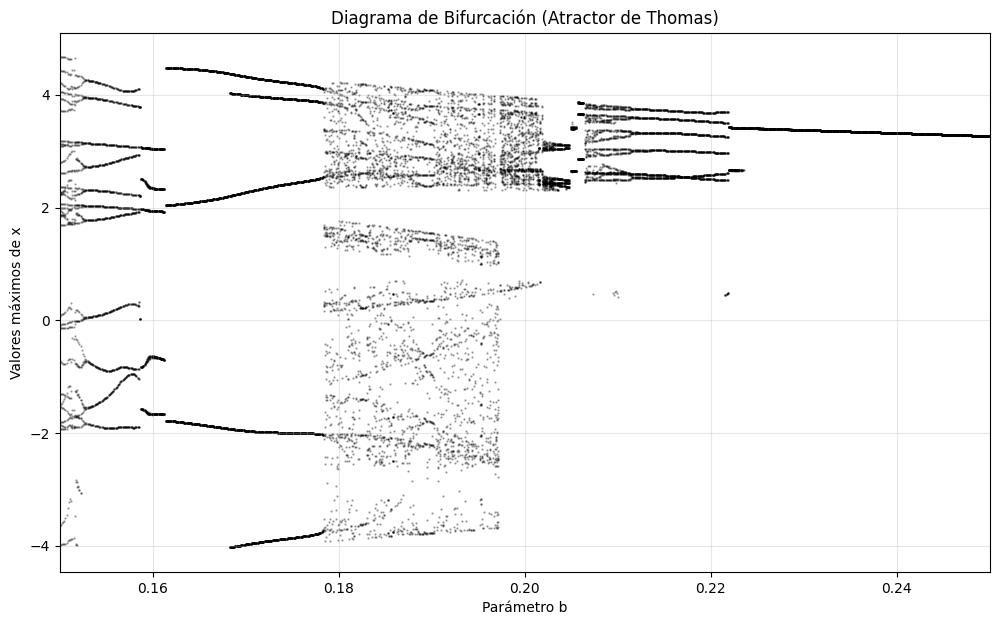

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import numba

# --- 1. FUNCIONES DE FÍSICA (Compiladas para velocidad) ---
@numba.njit
def thomas_deriv(state, b):
    x, y, z = state
    dx = np.sin(y) - b * x
    dy = np.sin(z) - b * y
    dz = np.sin(x) - b * z
    return np.array([dx, dy, dz])

@numba.njit
def rk4_step(state, b, dt):
    k1 = thomas_deriv(state, b)
    k2 = thomas_deriv(state + 0.5 * dt * k1, b)
    k3 = thomas_deriv(state + 0.5 * dt * k2, b)
    k4 = thomas_deriv(state + dt * k3, b)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

@numba.njit
def get_poincare_points_robust(b, x0, y0, z0, t_trans, t_eval, dt):
    state = np.array([x0, y0, z0], dtype=np.float64)
    points = []

    # 1. Transitorios
    steps_trans = int(t_trans / dt)
    for _ in range(steps_trans):
        state = rk4_step(state, b, dt)

    # 2. Recolección (Buscando picos)
    steps_eval = int(t_eval / dt)
    prev_x = state[0]
    state = rk4_step(state, b, dt)
    curr_x = state[0]

    for _ in range(steps_eval):
        state = rk4_step(state, b, dt)
        next_x = state[0]

        # Lógica de Pico: Es mayor que el anterior y mayor que el siguiente
        if curr_x > prev_x and curr_x > next_x:
            points.append(curr_x)

        prev_x = curr_x
        curr_x = next_x

    # --- SALVAVIDAS ---
    # Si no encontró picos, es probable que sea un Punto Fijo (línea plana).
    # Devolvemos el último valor de x para que al menos pinte la línea.
    if len(points) == 0:
        points.append(curr_x)

    return points

# --- 2. CONFIGURACIÓN ---
resolution = 800
b_min, b_max = 0.15, 0.25
b_vals = np.linspace(b_min, b_max, resolution)

plot_b = []
plot_x = []

print("Calculando... (Si esto termina rápido, el problema era visual)")

# --- 3. BUCLE DE CÁLCULO ---
for i, b in enumerate(b_vals):
    # Probamos con una condición inicial estándar
    # Bajamos un poco el dt para capturar mejor los picos finos
    puntos = get_poincare_points_robust(b, 1.0, 0.1, 0.1, t_trans=200, t_eval=300, dt=0.05)

    plot_b.extend([b] * len(puntos))
    plot_x.extend(puntos)

# DIAGNÓSTICO:
print(f"Se encontraron {len(plot_x)} puntos totales para graficar.")

# --- 4. GRAFICAR ---
if len(plot_x) > 0:
    plt.figure(figsize=(12, 7))

    # Aumenté 's' a 0.5 y bajé 'alpha' para ver densidad
    plt.scatter(plot_b, plot_x, s=0.5, c='black', alpha=0.3)

    plt.title("Diagrama de Bifurcación (Atractor de Thomas)")
    plt.xlabel("Parámetro b")
    plt.ylabel("Valores máximos de x")
    plt.xlim(b_min, b_max)

    # Quitamos el límite fijo de Y por si acaso tus valores son mayores
    # plt.ylim(-4, 4)
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("ERROR CRÍTICO: No se generaron datos. Revisa las ecuaciones o rangos.")

Calculando... (Si esto termina rápido, el problema era visual)
Se encontraron 18015 puntos totales para graficar.


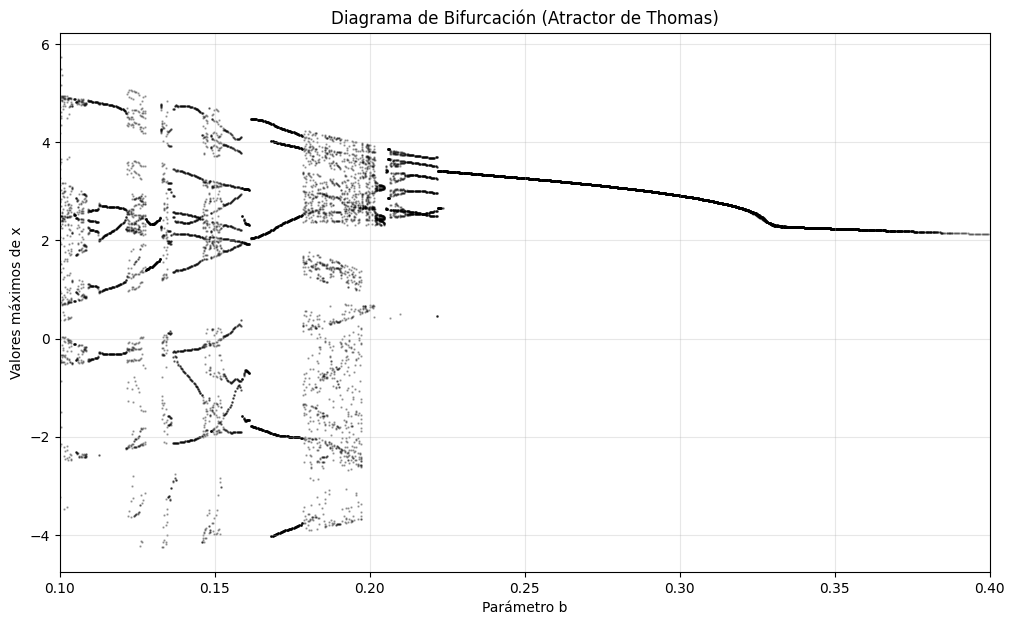

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import numba

# --- 1. FUNCIONES DE FÍSICA (Compiladas para velocidad) ---
@numba.njit
def thomas_deriv(state, b):
    x, y, z = state
    dx = np.sin(y) - b * x
    dy = np.sin(z) - b * y
    dz = np.sin(x) - b * z
    return np.array([dx, dy, dz])

@numba.njit
def rk4_step(state, b, dt):
    k1 = thomas_deriv(state, b)
    k2 = thomas_deriv(state + 0.5 * dt * k1, b)
    k3 = thomas_deriv(state + 0.5 * dt * k2, b)
    k4 = thomas_deriv(state + dt * k3, b)
    return state + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

@numba.njit
def get_poincare_points_robust(b, x0, y0, z0, t_trans, t_eval, dt):
    state = np.array([x0, y0, z0], dtype=np.float64)
    points = []

    # 1. Transitorios
    steps_trans = int(t_trans / dt)
    for _ in range(steps_trans):
        state = rk4_step(state, b, dt)

    # 2. Recolección (Buscando picos)
    steps_eval = int(t_eval / dt)
    prev_x = state[0]
    state = rk4_step(state, b, dt)
    curr_x = state[0]

    for _ in range(steps_eval):
        state = rk4_step(state, b, dt)
        next_x = state[0]

        # Lógica de Pico: Es mayor que el anterior y mayor que el siguiente
        if curr_x > prev_x and curr_x > next_x:
            points.append(curr_x)

        prev_x = curr_x
        curr_x = next_x

    # --- SALVAVIDAS ---
    # Si no encontró picos, es probable que sea un Punto Fijo (línea plana).
    # Devolvemos el último valor de x para que al menos pinte la línea.
    if len(points) == 0:
        points.append(curr_x)

    return points

# --- 2. CONFIGURACIÓN ---
resolution = 800
b_min, b_max = 0.1, 0.4
b_vals = np.linspace(b_min, b_max, resolution)

plot_b = []
plot_x = []

print("Calculando... (Si esto termina rápido, el problema era visual)")

# --- 3. BUCLE DE CÁLCULO ---
for i, b in enumerate(b_vals):
    # Probamos con una condición inicial estándar
    # Bajamos un poco el dt para capturar mejor los picos finos
    puntos = get_poincare_points_robust(b, 1.0, 0.1, 0.1, t_trans=200, t_eval=300, dt=0.05)

    plot_b.extend([b] * len(puntos))
    plot_x.extend(puntos)

# DIAGNÓSTICO:
print(f"Se encontraron {len(plot_x)} puntos totales para graficar.")

# --- 4. GRAFICAR ---
if len(plot_x) > 0:
    plt.figure(figsize=(12, 7))

    # Aumenté 's' a 0.5 y bajé 'alpha' para ver densidad
    plt.scatter(plot_b, plot_x, s=0.5, c='black', alpha=0.3)

    plt.title("Diagrama de Bifurcación (Atractor de Thomas)")
    plt.xlabel("Parámetro b")
    plt.ylabel("Valores máximos de x")
    plt.xlim(b_min, b_max)

    # Quitamos el límite fijo de Y por si acaso tus valores son mayores
    # plt.ylim(-4, 4)
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("ERROR CRÍTICO: No se generaron datos. Revisa las ecuaciones o rangos.")

<>:25: SyntaxWarning:

invalid escape sequence '\s'

<>:25: SyntaxWarning:

invalid escape sequence '\s'

/tmp/ipython-input-865607096.py:25: SyntaxWarning:

invalid escape sequence '\s'



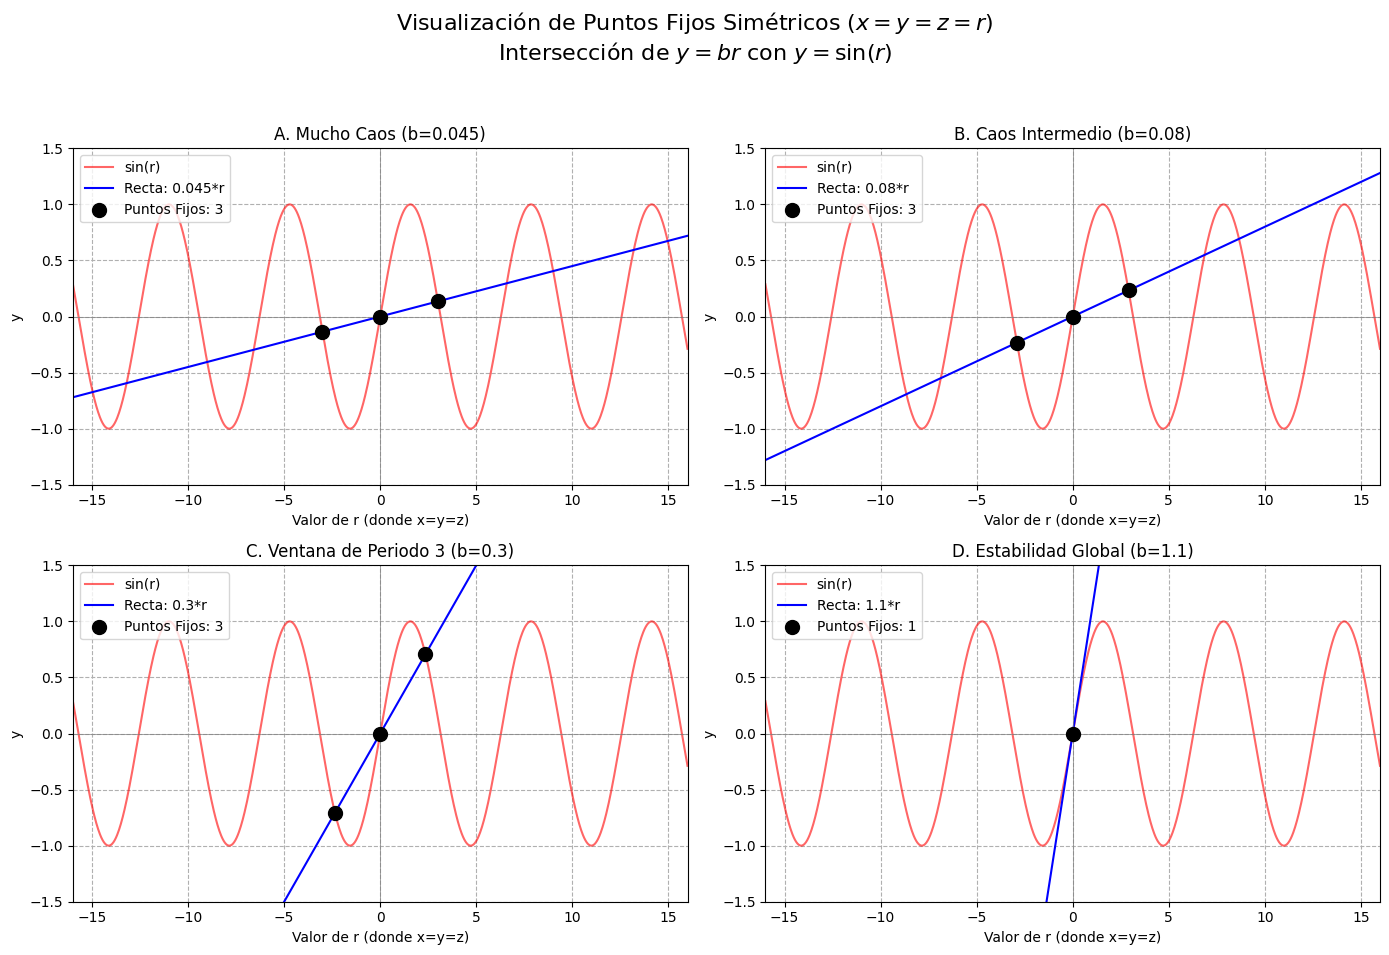

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# --- 1. Definición de la función a resolver ---
# Buscamos r tal que: b*r - sin(r) = 0
def funcion_objetivo(r, b):
    return b * r - np.sin(r)

# --- 2. Configuración de los escenarios ---
# Elegimos valores de 'b' que sabemos generan el número deseado de intersecciones.
# Nota: b debe ser mayor que 0.
escenarios = [
    {"b": 0.045, "target": 7, "titulo": "A. Mucho Caos (b=0.045)"},
    {"b": 0.08,  "target": 5, "titulo": "B. Caos Intermedio (b=0.08)"},
    {"b": 0.3,   "target": 3, "titulo": "C. Ventana de Periodo 3 (b=0.3)"},
    {"b": 1.1,   "target": 1, "titulo": "D. Estabilidad Global (b=1.1)"}
]

# Rango para graficar 'r' (necesitamos suficiente espacio para ver varias ondas)
r_plot = np.linspace(-16, 16, 1000)

# --- 3. Creación de la figura ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Visualización de Puntos Fijos Simétricos ($x=y=z=r$)\nIntersección de $y = br$ con $y = \sin(r)$', fontsize=16)
axes = axes.flatten()

# --- 4. Bucle principal: Analizar y graficar cada escenario ---
for i, escenario in enumerate(escenarios):
    b = escenario["b"]
    ax = axes[i]

    # a) Graficar las funciones base
    ax.plot(r_plot, np.sin(r_plot), 'r-', alpha=0.6, label='sin(r)')
    ax.plot(r_plot, b * r_plot, 'b-', label=f'Recta: {b}*r')

    # b) Encontrar las raíces numéricamente
    puntos_fijos_r = [0.0] # El origen siempre es un punto fijo

    # Buscamos raíces positivas en intervalos donde sabemos que están los picos del seno.
    # Los picos están en pi/2, 5pi/2, 9pi/2...
    # Usamos brentq que es un método robusto para encontrar raíces en un intervalo.
    intervalos_busqueda = [(0.1, np.pi), (np.pi, 3*np.pi), (3*np.pi, 5*np.pi)]

    for inicio, fin in intervalos_busqueda:
        # Verificamos si hay cambio de signo en el intervalo (condición para brentq)
        if funcion_objetivo(inicio, b) * funcion_objetivo(fin, b) < 0:
            raiz = brentq(funcion_objetivo, inicio, fin, args=(b,))
            puntos_fijos_r.append(raiz)
            puntos_fijos_r.append(-raiz) # Añadimos el simétrico negativo

    # Limpiamos y ordenamos la lista de puntos
    puntos_fijos_r = sorted(np.unique(np.array(puntos_fijos_r)))
    num_puntos = len(puntos_fijos_r)

    # c) Graficar los puntos fijos encontrados
    # Los graficamos sobre la curva seno
    ax.scatter(puntos_fijos_r, np.sin(puntos_fijos_r), color='black', s=100, zorder=5,
               label=f'Puntos Fijos: {num_puntos}')

    # d) Estética de la gráfica
    ax.set_title(escenario["titulo"])
    ax.set_xlabel('Valor de r (donde x=y=z)')
    ax.set_ylabel('y')
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_xlim(-16, 16)
    ax.grid(True, linestyle='--')
    ax.legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajustar espacio para el título principal
plt.show()